<a href="https://colab.research.google.com/github/Yuvraj030402/ai-engineer-learning/blob/main/car_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Car Price Prediction — learn one cell at a time

**Goal:** predict a used car's advertised selling price in **Indian rupees**.

This notebook uses the real **15,411-row CarDekho dataset** and the same two algorithms as your original notebook: **Linear Regression** and **Lasso Regression**.

In Google Colab: choose **Runtime → Run all**, or click the play button beside each code cell from top to bottom. A CPU runtime is enough. Colab already includes the libraries used here. No project helper files or API keys are needed.

The raw data is historical. The `vehicle_age` field is age recorded in that dataset, not manufacturing year. There is no passing/RTO or registration-expiry field. Predictions are practice estimates of historical listing prices, not live market quotations.

Dataset: https://www.kaggle.com/datasets/manishkr1754/cardekho-used-car-data

Public CSV supplied by the dataset creator: https://raw.githubusercontent.com/manishkr1754/CarDekho_Used_Car_Price_Prediction/main/notebooks/data/cardekho_dataset.csv


## 1. Import the tools

`pandas` reads tables; `matplotlib` draws charts; scikit-learn prepares data, trains models, and measures errors. `joblib` saves the complete trained pipeline.


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import urllib.request
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
print('scikit-learn:', sklearn.__version__)


scikit-learn: 1.9.1


## 2. Download and read the dataset

This cell downloads the CSV only when `car_data.csv` is absent. You do not need a Kaggle account. One row describes one advertised car.


In [2]:
DATA_URL = 'https://raw.githubusercontent.com/manishkr1754/CarDekho_Used_Car_Price_Prediction/main/notebooks/data/cardekho_dataset.csv'
DATA_PATH = Path('car_data.csv')
if not DATA_PATH.exists():
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        DATA_PATH.write_bytes(response.read())

raw = pd.read_csv(DATA_PATH)
print('Raw rows and columns:', raw.shape)
raw.head()


NameError: name 'DATA_PATH' is not defined

## 3. Understand the columns

**Inputs:** brand, model, car age, kilometres driven, fuel, transmission, seller, mileage, engine size, power, seats.

**Output:** `selling_price` in rupees. For example, `550000` means ₹5,50,000 (5.5 lakh).

The `Unnamed: 0` column is an exported row index, not a useful input. `car_name` repeats the brand and model, so we do not need it as an additional feature.


In [ ]:
raw.info()
print('Missing values:')
print(raw.isna().sum())
print('Fuel types:')
print(raw['fuel_type'].value_counts())
raw.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB
Missing values:
Unnamed: 0           0
car_name             0

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,9811.857699,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,5643.418542,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4906.500000,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,9872.000000,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,14668.500000,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,19543.000000,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


## 4. Clean the data before splitting

Remove the exported index first, convert numeric columns to numbers, remove missing/invalid essential values, and remove exact duplicate listings. This prevents identical listings from inflating both training and test results.

We keep legitimate expensive cars: a high price alone is not an invalid record.


In [ ]:
NUMERIC = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
CATEGORICAL = ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
FEATURES = NUMERIC + CATEGORICAL
TARGET = 'selling_price'

data = raw.loc[:, ~raw.columns.str.startswith('Unnamed')].copy()
for column in NUMERIC + [TARGET]:
    data[column] = pd.to_numeric(data[column], errors='coerce')
data = data.replace([np.inf, -np.inf], np.nan)
for column in CATEGORICAL:
    data[column] = data[column].astype('string').str.strip().replace('', pd.NA)
data = data.dropna(subset=FEATURES + [TARGET])
data = data[(data['vehicle_age'] >= 0) & (data['km_driven'] >= 0)]
for column in ['mileage', 'engine', 'max_power', 'seats', TARGET]:
    data = data[data[column] > 0]

invalid_rows_removed = len(raw) - len(data)
before_duplicates = len(data)
data = data.drop_duplicates().reset_index(drop=True)
duplicates_removed = before_duplicates - len(data)
print('Raw rows:', len(raw))
print('Invalid rows removed:', invalid_rows_removed)
print('Exact duplicates removed:', duplicates_removed)
print('Clean rows:', len(data))
data.head()


Raw rows: 15411
Invalid rows removed: 2
Exact duplicates removed: 167
Clean rows: 15242


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


## 5. Explore a few relationships

Look at how age and kilometres relate to price. The relationships will not be perfectly straight because brand, model, and other details also matter.


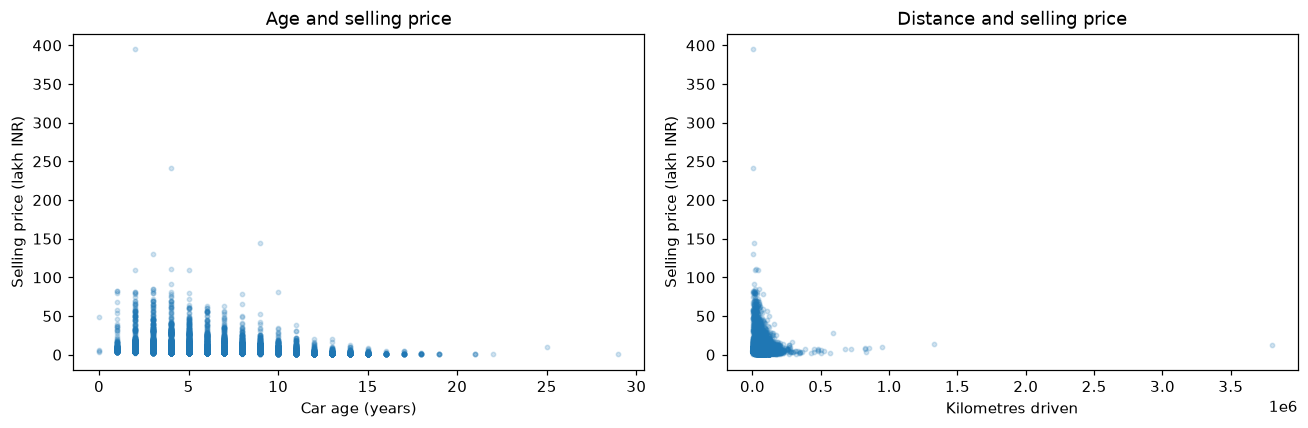

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(data['vehicle_age'], data['selling_price'] / 100000, s=8, alpha=0.2)
axes[0].set(xlabel='Car age (years)', ylabel='Selling price (lakh INR)', title='Age and selling price')
axes[1].scatter(data['km_driven'], data['selling_price'] / 100000, s=8, alpha=0.2)
axes[1].set(xlabel='Kilometres driven', ylabel='Selling price (lakh INR)', title='Distance and selling price')
plt.tight_layout()
plt.show()


## 6. Separate inputs X from the price y

`X` contains only details available before a prediction. `y` is the price to learn. The target price must never be included in `X`.


In [ ]:
X = data[FEATURES]
y = data[TARGET]
print('Input columns:', X.columns.tolist())
print('Input shape:', X.shape, '| Target shape:', y.shape)


Input columns: ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
Input shape: (15242, 11) | Target shape: (15242,)


## 7. Keep 20% for an honest final test

The model learns from 80% of the rows. We reserve 20% to evaluate it. `random_state=42` makes the split repeatable.

The test rows will not be used to fit scaling, encoding, or regression coefficients, or to choose the default algorithm.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))
assert set(X_train.index).isdisjoint(X_test.index)


Training rows: 12193
Test rows: 3049


## 8. Create one reusable preparation + regression pipeline

**One-hot encoding** converts text into yes/no columns, without pretending that Petrol=0 and Diesel=1 are quantities. `drop='first'` avoids the basic dummy-variable redundancy.

**StandardScaler** puts numeric inputs on comparable scales. This is especially useful for Lasso, which penalizes coefficients.

The **Pipeline** keeps preparation and regression together, ensuring the UI transforms new inputs exactly as training did. Scikit-learn fits preparation only on the training data supplied to `fit()`.


In [ ]:
def make_pipeline(regressor):
    preprocessing = ColumnTransformer([
        ('numbers', StandardScaler(), NUMERIC),
        ('categories', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([
        ('preprocessing', preprocessing),
        ('regression', regressor),
    ])


## 9. Train Linear Regression

Linear Regression learns an intercept and coefficients so that a weighted combination of the prepared features predicts price. The prepared text features are included in this same calculation.


In [ ]:
linear_model = make_pipeline(LinearRegression())
linear_model.fit(X_train, y_train)
print('Linear Regression is trained.')


Linear Regression is trained.


## 10. Train Lasso Regression

Lasso is linear regression with a coefficient penalty. It can shrink weak feature coefficients to zero. `alpha` controls the penalty.

Here the target is rupees, whereas your old notebook used lakh prices. Consequently, `alpha=1000` here cannot be compared directly with `alpha=1` in that notebook. This is a fixed learning example, not a claim that alpha=1000 is optimal.


In [ ]:
lasso_model = make_pipeline(Lasso(alpha=1000, max_iter=30000, tol=0.001))
lasso_model.fit(X_train, y_train)
models = {'Linear Regression': linear_model, 'Lasso Regression': lasso_model}
print('Lasso Regression is trained.')


Lasso Regression is trained.


## 11. Compare algorithms using training data only

Three-fold cross-validation repeatedly fits on part of the training set and validates on the rest. We choose the default algorithm with the **lowest validation MAE**. The final test set stays untouched.

The scoring function returns negative MAE because scikit-learn treats bigger scores as better; the minus sign below converts it back into a positive rupee error.


In [ ]:
folds = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, model in models.items():
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        cv_results[name] = float(-cross_val_score(
            model, X_train, y_train, cv=folds,
            scoring='neg_mean_absolute_error', n_jobs=1
        ).mean())

selected_model = min(cv_results, key=cv_results.get)
print(pd.Series(cv_results, name='Validation MAE (INR)'))
print('Default model:', selected_model)


Linear Regression    178609.899645
Lasso Regression     207700.350048
Name: Validation MAE (INR), dtype: float64
Default model: Linear Regression


## 12. Evaluate on the test set

- **R²:** how well predictions explain price variation relative to a mean-price baseline. It is **not percentage accuracy** and may be negative.
- **MAE:** average absolute error in rupees. Smaller is better.
- **RMSE:** rupee error that penalizes large misses more strongly. Smaller is better.

Training R² and test R² help reveal a gap between fitting known rows and predicting unseen rows. We report the raw model predictions, without hiding negative outputs by clipping them.


In [ ]:
results = {}
test_predictions = []
for name, model in models.items():
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        predicted = model.predict(X_test)
    results[name] = {
        'train_r2': float(r2_score(y_train, model.predict(X_train))),
        'test_r2': float(r2_score(y_test, predicted)),
        'mae': float(mean_absolute_error(y_test, predicted)),
        'rmse': float(np.sqrt(mean_squared_error(y_test, predicted))),
        'cv_mae': cv_results[name],
        'nonpositive_test_predictions': int((predicted <= 0).sum()),
    }
    test_predictions.extend(
        {'actual': float(actual), 'predicted': float(estimate), 'model_name': name}
        for actual, estimate in zip(y_test.iloc[:150], predicted[:150])
    )

score_table = pd.DataFrame(results).T
score_table


,train_r2,test_r2,mae,rmse,cv_mae,nonpositive_test_predictions
Linear Regression,0.849932,0.656102,176820.558409,528255.308589,178609.899645,96.0
Lasso Regression,0.785202,0.695632,204295.279005,496968.005595,207700.350048,124.0


## 13. Compare against a very simple baseline

A median baseline always predicts the median training price, regardless of the car. A useful model should improve on that baseline's test error.


In [ ]:
baseline = DummyRegressor(strategy='median')
baseline.fit(X_train, y_train)
baseline_mae = float(mean_absolute_error(y_test, baseline.predict(X_test)))
print(f'Median baseline MAE: INR {baseline_mae:,.0f}')
print(f'{selected_model} test MAE: INR {results[selected_model]["mae"]:,.0f}')


Median baseline MAE: INR 394,142
Linear Regression test MAE: INR 176,821


## 14. Plot actual prices against predictions

Points close to the dashed diagonal have smaller errors. Compare a few low-price and high-price cars; a good overall score can still hide errors for particular models.


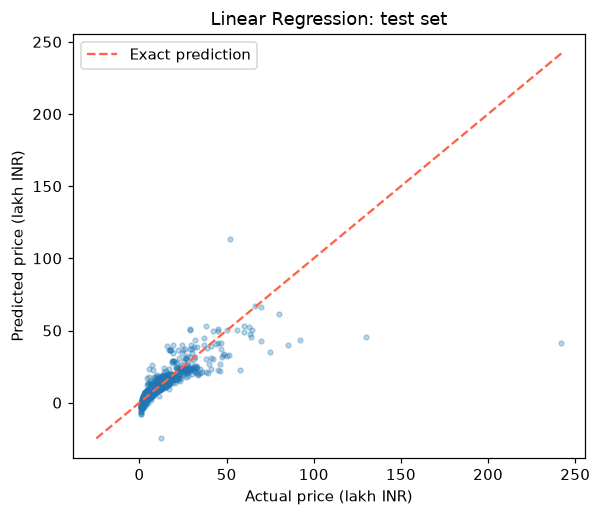

In [ ]:
best_model = models[selected_model]
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')
    predictions = best_model.predict(X_test)
plt.figure(figsize=(6, 5))
plt.scatter(y_test / 100000, predictions / 100000, s=10, alpha=0.3)
low = float(min(y_test.min(), predictions.min())) / 100000
high = float(max(y_test.max(), predictions.max())) / 100000
plt.plot([low, high], [low, high], '--', color='tomato', label='Exact prediction')
plt.xlabel('Actual price (lakh INR)')
plt.ylabel('Predicted price (lakh INR)')
plt.title(selected_model + ': test set')
plt.legend()
plt.show()


## 15. Predict one car — edit this cell yourself

Change the values below and run this cell again. `vehicle_age=5` means five years old in the dataset's sense; it is not a manufacturing year.

All specifications are provided explicitly here. In the UI, optional technical values are prefilled with medians from similar dataset cars and remain editable.


In [ ]:
new_car = pd.DataFrame([{
    'brand': 'Maruti',
    'model': 'Swift',
    'vehicle_age': 5,
    'km_driven': 45000,
    'seller_type': 'Individual',
    'fuel_type': 'Petrol',
    'transmission_type': 'Manual',
    'mileage': 21.0,
    'engine': 1197,
    'max_power': 82.0,
    'seats': 5,
}])

with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')
    estimated_price = float(best_model.predict(new_car[FEATURES])[0])
if estimated_price > 0:
    print(f'Estimated price: INR {estimated_price:,.0f}')
    print(f'Estimated price: {estimated_price / 100000:.2f} lakh')
else:
    print('This linear model returned a non-positive price; no valid price estimate is available.')
print('Model:', selected_model)


Estimated price: INR 547,043
Estimated price: 5.47 lakh
Model: Linear Regression


## 16. Inspect what Linear Regression learned

Each coefficient belongs to a scaled numeric feature or an encoded category. It describes a conditional relationship in this fitted model, not a causal rule. Correlated features make individual coefficients harder to interpret.


In [ ]:
feature_names = linear_model.named_steps['preprocessing'].get_feature_names_out()
coefficient_table = pd.DataFrame({
    'prepared_feature': feature_names,
    'coefficient': linear_model.named_steps['regression'].coef_,
})
coefficient_table['absolute_coefficient'] = coefficient_table['coefficient'].abs()
coefficient_table.sort_values('absolute_coefficient', ascending=False).head(15)


,prepared_feature,coefficient,absolute_coefficient
9,categories__brand_Ferrari,1.713078e+07,1.713078e+07
84,categories__model_GTC4Lusso,1.713078e+07,1.713078e+07
63,categories__model_Continental,3.649332e+06,3.649332e+06
7,categories__brand_Bentley,3.649332e+06,3.649332e+06
138,categories__model_X4,3.226118e+06,3.226118e+06
82,categories__model_GLS,2.929914e+06,2.929914e+06
37,categories__model_6,2.587057e+06,2.587057e+06
139,categories__model_X5,2.432344e+06,2.432344e+06
149,categories__model_Z4,2.263478e+06,2.263478e+06
23,categories__brand_Maruti,-2.049765e+06,2.049765e+06


## 17. Save both complete pipelines and metrics

`model.joblib` contains both algorithms and their fitted preprocessing. The following metadata matches what the Streamlit app needs. You can place these generated files beside `app.py` in the project folder.

Only load serialized models you created or otherwise trust. Colab's scikit-learn version may differ from the local environment; if the app requests retraining, run `train.py` in the app's environment instead.


In [ ]:
metrics = {
    'raw_rows': len(raw), 'clean_rows': len(data),
    'duplicates_removed': duplicates_removed, 'invalid_rows_removed': invalid_rows_removed,
    'train_rows': len(X_train), 'test_rows': len(X_test), 'random_state': RANDOM_STATE,
    'selected_model': selected_model, 'models': results, 'baseline_mae': baseline_mae,
    'trained_at_utc': datetime.now(timezone.utc).isoformat(),
    'sklearn_version': sklearn.__version__, 'artifact_version': 1,
    'source_url': DATA_URL, 'source_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'target': TARGET, 'target_unit': 'INR', 'features': FEATURES,
    'feature_ranges': {column: [float(X_train[column].min()), float(X_train[column].max())] for column in NUMERIC},
    'seen_categories': {column: sorted(X_train[column].unique().tolist()) for column in CATEGORICAL},
    'test_predictions': test_predictions,
    'selection_method': 'Lowest 3-fold cross-validation MAE on training rows only.',
    'scope': 'Historical advertised used-car prices; no current market, RTO, or registration data.',
}
artifacts = {'models': models, 'metrics': metrics}
joblib.dump(artifacts, 'model.joblib', compress=3)
Path('metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print('Saved: model.joblib and metrics.json')


Saved: model.joblib and metrics.json


## 18. Reload the model and check the prediction

The app follows this same pattern: load the pipeline, construct one row with the same feature names, and call `predict()`.


In [ ]:
loaded = joblib.load('model.joblib')
reloaded_prediction = float(loaded['models'][selected_model].predict(new_car[FEATURES])[0])
assert np.isclose(estimated_price, reloaded_prediction)
print('Reloaded prediction matches:', np.isclose(estimated_price, reloaded_prediction))


Reloaded prediction matches: True


## 19. Optional: download your files from Colab

Run this cell if you want to save the trained files on your computer. When running locally, it simply prints their locations.


In [ ]:
try:
    from google.colab import files
except ImportError:
    print('Local model:', Path('model.joblib').resolve())
    print('Local metrics:', Path('metrics.json').resolve())
else:
    files.download('model.joblib')
    files.download('metrics.json')


Local model: D:\G39\.car-build\model.joblib
Local metrics: D:\G39\.car-build\metrics.json


## What to try next

1. Change `km_driven` and age in Step 15 and compare the predictions.
2. Try `alpha=100`, `1000`, and `10000` for Lasso and compare training cross-validation MAE.
3. Keep the test set untouched while choosing those settings.
4. Look at cars with large test errors before trying more complex regression algorithms.

Your original notebook's stored scores were Linear Regression test R² **0.8366** and Lasso test R² **0.8709**. This new dataset, target units, and split differ, so scores are not directly comparable. The project includes `NOTEBOOK_REVIEW.md` with a cell-by-cell review of your original work.
